In [17]:
# Install extra boosters if not already installed
!pip install xgboost lightgbm -q

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Cooperative worker gig platform project/smart_worker_allocation_20000_v2 (2).csv")

print(f"[*] Dataset successfully loaded with shape: {df.shape}")
df.head()

[*] Dataset successfully loaded with shape: (20000, 17)


,booking_id,worker_id,service_category,skill_name,quantity,scheduled_hour,day_of_week,worker_category,experience_years,certifications_count,has_certifications,is_verified,distance_km,worker_skill_price,worker_skill_price_type,platform_tenure_days,successful_completion
0,B00001,W00381,Plumber,Leak Repair,2,20,6,Plumber,1.6,1,1,0,4.66,417.10,per_hour,2343,0
1,B00001,W00104,Plumber,Leak Repair,2,20,6,Plumber,4.7,1,1,1,2.82,602.40,per_hour,1104,0
2,B00001,W00359,Plumber,Leak Repair,2,20,6,Plumber,3.9,1,1,0,8.58,546.42,per_visit,2676,0
3,B00001,W00280,Plumber,Leak Repair,2,20,6,Plumber,4.4,1,1,1,5.75,521.26,per_day,267,0
4,B00001,W00889,Plumber,Leak Repair,2,20,6,Plumber,9.2,3,1,1,3.77,658.39,per_visit,2867,1


In [19]:
df.columns = [col.strip() for col in df.columns]

print(f"Dataset Shape: {df.shape}")
print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values per column:")
print(df.isnull().sum())

Dataset Shape: (20000, 17)

First 5 rows:


,booking_id,worker_id,service_category,skill_name,quantity,scheduled_hour,day_of_week,worker_category,experience_years,certifications_count,has_certifications,is_verified,distance_km,worker_skill_price,worker_skill_price_type,platform_tenure_days,successful_completion
0,B00001,W00381,Plumber,Leak Repair,2,20,6,Plumber,1.6,1,1,0,4.66,417.10,per_hour,2343,0
1,B00001,W00104,Plumber,Leak Repair,2,20,6,Plumber,4.7,1,1,1,2.82,602.40,per_hour,1104,0
2,B00001,W00359,Plumber,Leak Repair,2,20,6,Plumber,3.9,1,1,0,8.58,546.42,per_visit,2676,0
3,B00001,W00280,Plumber,Leak Repair,2,20,6,Plumber,4.4,1,1,1,5.75,521.26,per_day,267,0
4,B00001,W00889,Plumber,Leak Repair,2,20,6,Plumber,9.2,3,1,1,3.77,658.39,per_visit,2867,1



Missing values per column:
booking_id                 0
worker_id                  0
service_category           0
skill_name                 0
quantity                   0
scheduled_hour             0
day_of_week                0
worker_category            0
experience_years           0
certifications_count       0
has_certifications         0
is_verified                0
distance_km                0
worker_skill_price         0
worker_skill_price_type    0
platform_tenure_days       0
successful_completion      0
dtype: int64


In [20]:
# Target label
target_col = 'successful_completion'

# Drop IDs that do not generalize
cols_to_drop = [c for c in ['booking_id', 'worker_id', target_col] if c in df.columns]

X = df.drop(columns=cols_to_drop)
y = df[target_col].astype(int)

print(f"Features shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")
print("\nTarget Class Distribution (%):")
print(y.value_counts(normalize=True) * 100)

Features shape (X): (20000, 14)
Target shape (y): (20000,)

Target Class Distribution (%):
successful_completion
0    50.035
1    49.965
Name: proportion, dtype: float64


In [21]:
# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Identify column types
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Numeric Columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical Columns ({len(categorical_cols)}): {categorical_cols}")


Numeric Columns (10): ['quantity', 'scheduled_hour', 'day_of_week', 'experience_years', 'certifications_count', 'has_certifications', 'is_verified', 'distance_km', 'worker_skill_price', 'platform_tenure_days']
Categorical Columns (4): ['service_category', 'skill_name', 'worker_category', 'worker_skill_price_type']


In [22]:
# Preprocessors
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, numeric_cols),
    ('cat', cat_transformer, categorical_cols)
])

In [23]:
# Fit on training data, transform test data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"\nProcessed Train Matrix shape: {X_train_processed.shape}")
print(f"Processed Test Matrix shape: {X_test_processed.shape}")


Processed Train Matrix shape: (16000, 68)
Processed Test Matrix shape: (4000, 68)


In [24]:
# Define dictionary of models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=120, learning_rate=0.1, max_depth=5, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=150, learning_rate=0.08, max_depth=5, eval_metric='logloss', random_state=42, n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=150, learning_rate=0.08, max_depth=6, random_state=42, n_jobs=-1, verbose=-1)
}

results = []
trained_models = {}

print("Training models...")
for name, model in models.items():
    print(f"  -> Fitting {name}...")
    model.fit(X_train_processed, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test_processed)

    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test_processed)[:, 1]
        auc = roc_auc_score(y_test, y_proba)
    else:
        auc = np.nan

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1 Score": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "ROC-AUC": round(auc, 4)
    })

# Convert to DataFrame & sort by best F1 score
results_df = pd.DataFrame(results).sort_values(by="F1 Score", ascending=False).reset_index(drop=True)

print("\n" + "="*70)
print("FINAL BENCHMARK COMPARISON TABLE")
print("="*70)
display(results_df)

Training models...
  -> Fitting Logistic Regression...
  -> Fitting Decision Tree...
  -> Fitting Random Forest...
  -> Fitting Gradient Boosting...
  -> Fitting Extra Trees...
  -> Fitting XGBoost...
  -> Fitting LightGBM...

FINAL BENCHMARK COMPARISON TABLE


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.6058,0.6001,0.6328,0.6160,0.6482
1,Logistic Regression,0.6042,0.6003,0.6228,0.6113,0.6513
2,XGBoost,0.5988,0.5933,0.6268,0.6096,0.6423
3,Gradient Boosting,0.6008,0.5965,0.6213,0.6087,0.6418
4,LightGBM,0.5978,0.5937,0.6183,0.6057,0.6408
5,Extra Trees,0.5860,0.5795,0.6253,0.6015,0.6274
6,Decision Tree,0.5843,0.5797,0.6113,0.5951,0.6128


Top Performing Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.58      0.59      2001
           1       0.60      0.63      0.62      1999

    accuracy                           0.61      4000
   macro avg       0.61      0.61      0.61      4000
weighted avg       0.61      0.61      0.61      4000



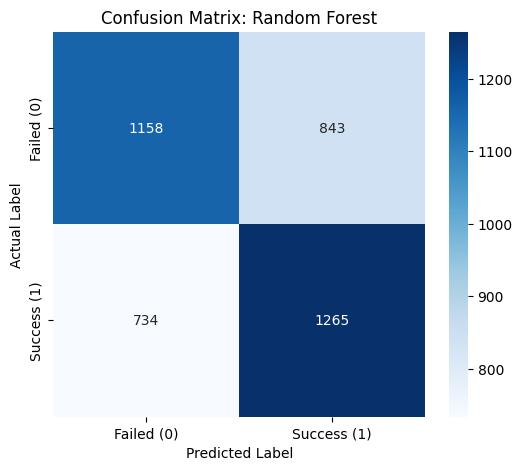

In [25]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print(f"Top Performing Model: {best_model_name}\n")

best_preds = best_model.predict(X_test_processed)

print("Classification Report:")
print(classification_report(y_test, best_preds))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, best_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Failed (0)', 'Success (1)'],
            yticklabels=['Failed (0)', 'Success (1)'])
plt.title(f"Confusion Matrix: {best_model_name}")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


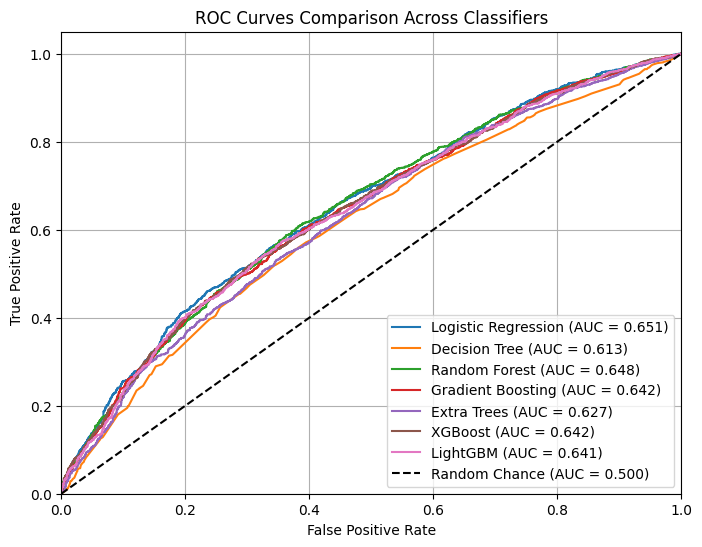

In [26]:
plt.figure(figsize=(8, 6))

for name, model in trained_models.items():
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_processed)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        auc = roc_auc_score(y_test, y_prob)
        plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label="Random Chance (AUC = 0.500)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Comparison Across Classifiers")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

/tmp/ipykernel_1721/2044970022.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df, x="Importance", y="Feature", palette="Blues_r")


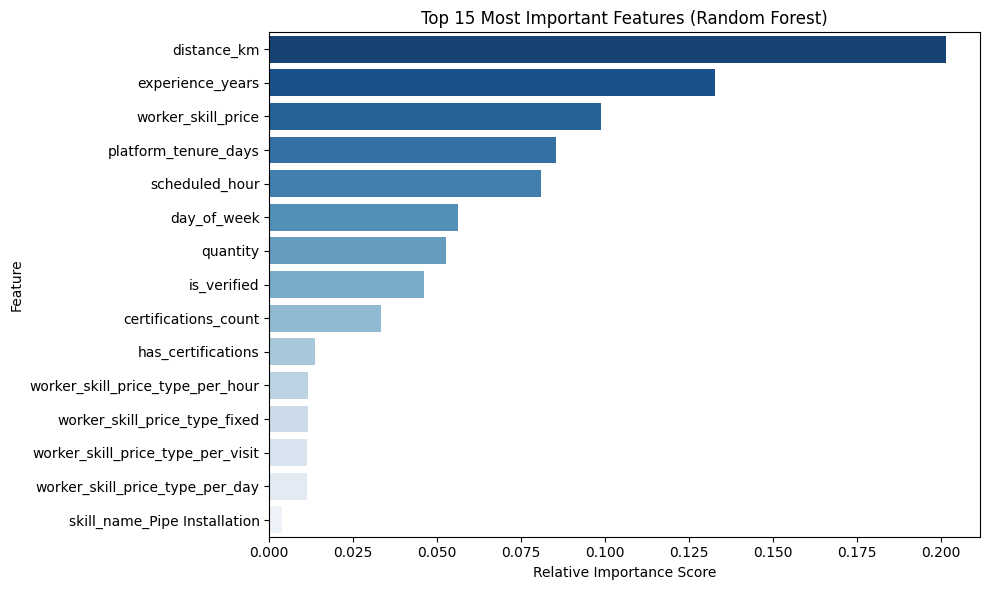

In [27]:
# Retrieve feature names after one-hot encoding
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
cat_encoded_cols = cat_encoder.get_feature_names_out(categorical_cols).tolist()
all_features = numeric_cols + cat_encoded_cols

# Check if best model supports feature importances (Tree/Ensemble models)
if hasattr(best_model, "feature_importances_"):
    importances = best_model.feature_importances_
    feat_df = pd.DataFrame({
        "Feature": all_features,
        "Importance": importances
    }).sort_values(by="Importance", ascending=False).head(15)

    plt.figure(figsize=(10, 6))
    sns.barplot(data=feat_df, x="Importance", y="Feature", palette="Blues_r")
    plt.title(f"Top 15 Most Important Features ({best_model_name})")
    plt.xlabel("Relative Importance Score")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
else:
    print(f"{best_model_name} does not provide tree-based feature importances.")